# Avance 1 — Capítulo 7: Machine Learning para series de tiempo

**Por:**
* Diego de Jesús Muñoz González.
* Alexander Góngora Venegas.

**Práctica de Deep Learning para Finanzas · BTC-USD diario**

**Objetivo del avance:** preparar datos confiables y establecer referencias que permitan valorar después el aporte del modelo profundo.
Se predice, al cierre del día *t*, el rendimiento del siguiente día: **y<sub>t</sub> = P<sub>t+1</sub> / P<sub>t</sub> − 1**, usando los **20 rendimientos más recientes** hasta *t*.

**Entregables de este avance (según el protocolo):**
1. Ficha del activo, auditoría de datos y **separación TR–VA–TE** (secciones 1, 2, 4).
2. **Pronóstico cero** y **regresión lineal** con los mismos rezagos; **MAE y RMSE en TR y VA** — *TE no se usa todavía* (sección 5).
3. **Gráficas** de precio, rendimientos y volatilidad histórica; identificación de faltantes, valores extremos y cambios de comportamiento (sección 3).
4. **Hipótesis técnica** verificable (sección 6).
5. Seguimiento: qué tendría que mejorar DL frente a pronosticar cero, y comprobaciones de alineación temporal y del escalador ajustado solo con TR (sección 7).

*Este avance se ejecuta en CPU; no requiere GPU.* Ejecución desde sesión limpia: **Ejecutar todo** (Jupyter, VS Code o Colab con la carpeta completa).

In [ ]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def _buscar_raiz():
    if os.environ.get("AVANCE1_RAIZ"):
        return Path(os.environ["AVANCE1_RAIZ"])
    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive")
        for cand in ("/content/drive/MyDrive/avance1_capitulo7", "/content/drive/MyDrive/Avance 1 Capitulo 7"):
            if (Path(cand) / "dlfin").exists():
                return Path(cand)
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "dlfin").exists() and (p / "datos").exists():
            return p
    raise FileNotFoundError("No se encontró la carpeta del avance (debe contener 'dlfin/' y 'datos/'). Defina AVANCE1_RAIZ.")

RAIZ = _buscar_raiz(); sys.path.insert(0, str(RAIZ))
from dlfin import data, features as F, metrics as M
from dlfin.errors import Bitacora, FugaError

SALIDA = RAIZ / "salidas"; (SALIDA / "figuras").mkdir(parents=True, exist_ok=True)
VENTANA, SEMILLA = 20, 42
bit = Bitacora()
print("Carpeta del avance:", RAIZ)

Carpeta del avance: C:\Users\alexg\Documents\Escuela\Quinto Semestre\Ciencia de Datos\Proyecto_final\Avance 1 Capitulo 7


## 1. Ficha del activo (fuente y diccionario de datos)
Se registran fuente, fecha de descarga, periodo, moneda, zona horaria y tratamiento de ajustes (requisito del protocolo).

In [ ]:
orig = RAIZ / "datos" / "originales"
ficha = json.loads((orig / "ficha_activo.json").read_text(encoding="utf-8"))
descargas = pd.read_csv(orig / "descargas_btc_usd_1d.csv")
ficha_tabla = pd.Series({
    "Activo": f"{ficha['nombre']} ({ficha['ticker']})",
    "Mercado mostrado": "Criptomonedas: un par de criptomoneda y moneda cotizada (BTC / USD)",
    "Plataforma de origen": "Yahoo Finance (agregador) vía yfinance",
    "Versión(es) yfinance": ", ".join(sorted(descargas["version_yfinance"].dropna().unique())),
    "Fecha de la última descarga (UTC)": descargas["ejecutado_utc"].max(),
    "Periodo solicitado": ", ".join(sorted(descargas["period_solicitado"].dropna().unique())) + " (diario, 1d)",
    "Moneda cotizada": ficha["moneda"],
    "Zona horaria": ficha["zona_horaria"] + " (la vela diaria cierra a las 00:00 UTC)",
    "Calendario": "Continuo 24/7 (no hay días sin negociación)",
    "Tratamiento de ajustes": f"auto_adjust={int(descargas['auto_adjust'].iloc[-1])}; adj_close = close (en cripto no hay dividendos ni particiones)",
    "Volumen": "Proporcionado por la fuente; no se inventa ni se rellena",
})
display(ficha_tabla.to_frame("valor"))
diccionario = pd.DataFrame([
    ("fecha", "Fecha de la sesión diaria (UTC)"), ("open", "Precio de apertura (USD)"), ("high", "Precio máximo (USD)"),
    ("low", "Precio mínimo (USD)"), ("close", "Precio de cierre (USD): base del rendimiento y del objetivo"),
    ("adj_close", "Cierre ajustado (idéntico a close)"), ("volume", "Volumen negociado (USD) según la fuente"),
    ("ret", "Rendimiento simple: P_t / P_(t-1) − 1"), ("y", "Objetivo: P_(t+1) / P_t − 1"),
], columns=["columna", "descripcion"])
display(diccionario)
diccionario.to_csv(SALIDA / "diccionario_datos.csv", index=False, encoding="utf-8")
ficha_tabla.to_frame("valor").to_csv(SALIDA / "ficha_activo.csv", encoding="utf-8")

,valor
Activo,Bitcoin (BTC-USD)
Mercado mostrado,Criptomonedas: un par de criptomoneda y moneda...
Plataforma de origen,Yahoo Finance (agregador) vía yfinance
Versión(es) yfinance,"1.7.0, 1.8.0"
Fecha de la última descarga (UTC),2026-11-03T21:44:13+00:00
Periodo solicitado,"5y (diario, 1d)"
Moneda cotizada,USD
Zona horaria,UTC (la vela diaria cierra a las 00:00 UTC)
Calendario,Continuo 24/7 (no hay días sin negociación)
Tratamiento de ajustes,auto_adjust=0; adj_close = close (en cripto no...


,columna,descripcion
0,fecha,Fecha de la sesión diaria (UTC)
1,open,Precio de apertura (USD)
2,high,Precio máximo (USD)
3,low,Precio mínimo (USD)
4,close,Precio de cierre (USD): base del rendimiento y...
5,adj_close,Cierre ajustado (idéntico a close)
6,volume,Volumen negociado (USD) según la fuente
7,ret,Rendimiento simple: P_t / P_(t-1) − 1
8,y,Objetivo: P_(t+1) / P_t − 1


## 2. Auditoría y limpieza de datos
Se audita **sin modificar el archivo original**: orden, fechas duplicadas, faltantes, infinitos, precios no positivos, incoherencias (low > high), volumen y huecos de calendario.

In [ ]:
crudo = pd.read_csv(orig / "btc_usd_1d_original.csv")
auditoria = data.auditar(crudo)
display(pd.Series(auditoria, name="auditoría").to_frame())

,auditoría
filas,1853
fecha_min,2021-10-07
fecha_max,2026-11-02
fechas_duplicadas,0
fuera_de_orden,0
faltantes_por_columna,{}
infinitos,0
precios_no_positivos,0
low_mayor_que_high,0
volumen_negativo,0


**Regla de limpieza (documentada, sin usar información futura ni rellenar huecos):**
1) ordenar por fecha; 2) si hay fechas duplicadas conservar la última descarga; 3) eliminar filas con NaN/inf o precios ≤ 0 (se registran fechas y columnas);
4) **no** se inventa volumen ni se rellenan días. Se registra cuántas filas cambian.

In [ ]:
d, rep_limpieza = data.limpiar(crudo, bit)
print("Filas que cambian por la limpieza:", rep_limpieza)
data.exigir_minimo(d, 1500)          # el protocolo exige >= 1,500 observaciones válidas antes de construir ventanas
print(f"Observaciones válidas: {len(d)}  (≥ 1,500 ✔)   {d.fecha.min().date()} → {d.fecha.max().date()}")
assert d["fecha"].is_unique and d["fecha"].is_monotonic_increasing and np.isfinite(d[data.PRECIOS].to_numpy()).all()
proc = RAIZ / "datos" / "procesados"; proc.mkdir(parents=True, exist_ok=True)
d.to_csv(proc / "btc_usd_1d_procesado.csv", index=False)
(proc / "auditoria.json").write_text(json.dumps({**auditoria, "limpieza": rep_limpieza}, indent=2, default=str), encoding="utf-8")
print("Datos procesados guardados en", proc)

Filas que cambian por la limpieza: {'entrada': 1853, 'reordenadas': 0, 'duplicadas_eliminadas': 0, 'invalidas_eliminadas': 0, 'salida': 1853}
Observaciones válidas: 1853  (≥ 1,500 ✔)   2021-10-07 → 2026-11-02
Datos procesados guardados en C:\Users\alexg\Documents\Escuela\Quinto Semestre\Ciencia de Datos\Proyecto_final\Avance 1 Capitulo 7\datos\procesados


### Identificación de faltantes y valores extremos

In [ ]:
faltantes = d.isna().sum().to_frame("faltantes"); display(faltantes.T)
ext = data.extremos(d, 10); display(ext)
print(f"Rendimientos con |z robusto| > 6 (MAD): {auditoria['rendimientos_extremos(|z_robusto|>6)']}  | min {auditoria['rendimiento_min']:.2%} | max {auditoria['rendimiento_max']:.2%}")

,fecha,open,high,low,close,adj_close,volume
faltantes,0,0,0,0,0,0,0


,fecha,close,rendimiento
249,2022-06-13,22487.388672,-0.159747
144,2022-02-28,43193.234375,0.145412
398,2022-11-09,15880.780273,-0.143490
1582,2026-02-05,62702.097656,-0.141299
1583,2026-02-06,70555.390625,0.125248
1036,2024-08-08,61710.136719,0.121443
120,2022-02-04,41500.875000,0.116978
214,2022-05-09,30296.953125,-0.110464
399,2022-11-10,17586.771484,0.107425
337,2022-09-09,21381.152344,0.106122


Rendimientos con |z robusto| > 6 (MAD): 7  | min -15.97% | max 14.54%


**Lectura.** No hay faltantes, duplicados, huecos de calendario, infinitos ni precios no positivos, y el volumen nunca es cero. Los rendimientos extremos
(≈ −16 % el 2022-06-13, +14.5 % el 2022-02-28, −14.1 % el 2026-02-05) son movimientos reales del mercado: **no se eliminan ni se recortan** (recortar usaría información de toda la muestra y ocultaría el riesgo real del activo).

## 3. Precio, rendimientos y volatilidad histórica

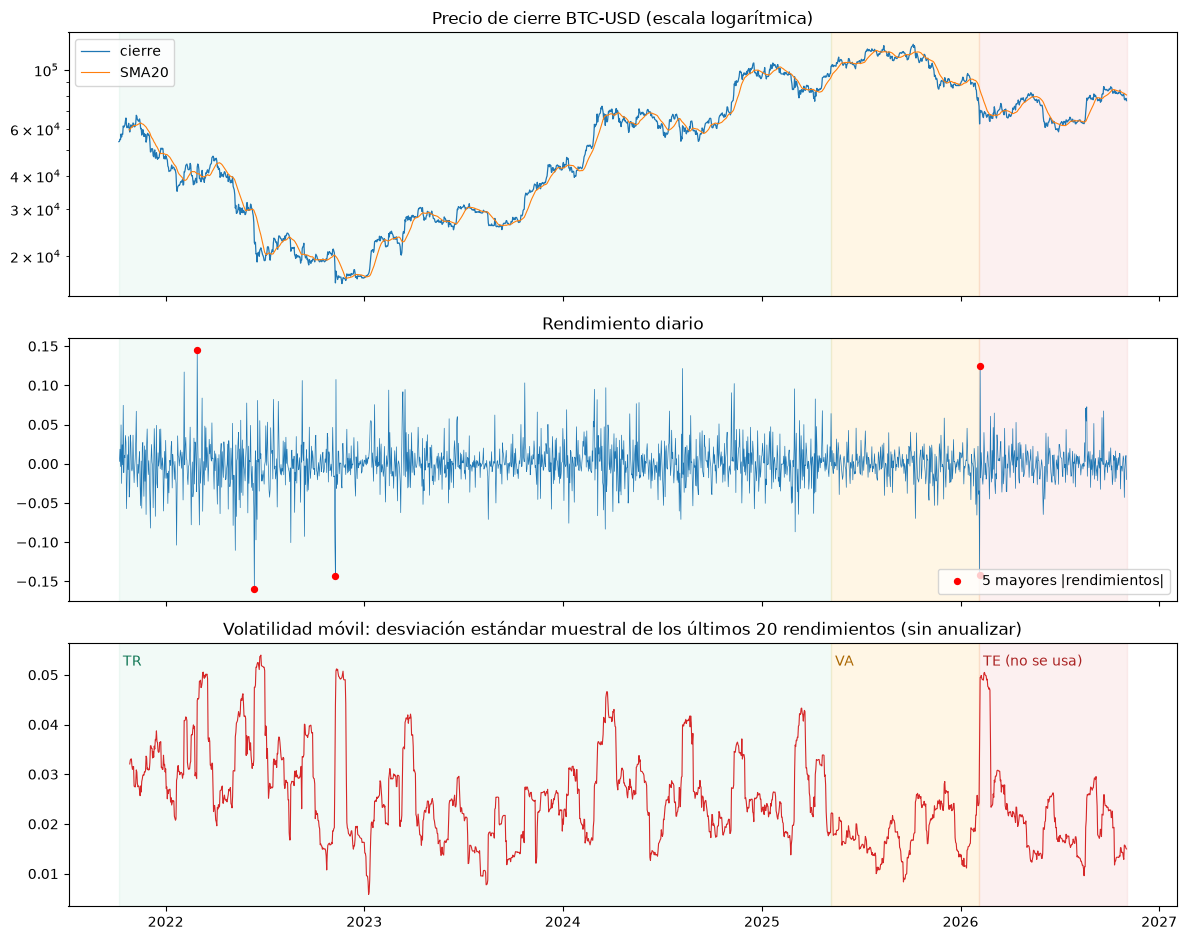

In [ ]:
ind = F.indicadores(d)
# Particiones (se calculan en la sección 4; aquí solo se sombrean para ubicar TE sin usarlo en ninguna métrica)
ej = F.construir_ejemplos(d, VENTANA, ("ret",), canales_para_inicio=F.CANALES_BASE)
idx = F.particionar(ej)
f_va0, f_te0 = ej.fecha_objetivo[idx["VA"]].min(), ej.fecha_objetivo[idx["TE"]].min()

fig, ax = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
ax[0].plot(ind.fecha, ind.close, lw=0.9, label="cierre"); ax[0].plot(ind.fecha, ind.sma20, lw=0.8, label="SMA20")
ax[0].set_yscale("log"); ax[0].set_title("Precio de cierre BTC-USD (escala logarítmica)"); ax[0].legend(loc="upper left")
ax[1].plot(ind.fecha, ind.ret, lw=0.5, color="C0")
mx = ext.head(5); ax[1].scatter(mx.fecha, mx.rendimiento, color="red", s=18, zorder=3, label="5 mayores |rendimientos|"); ax[1].legend(loc="lower right")
ax[1].set_title("Rendimiento diario")
ax[2].plot(ind.fecha, ind.vol20, lw=0.8, color="C3"); ax[2].set_title("Volatilidad móvil: desviación estándar muestral de los últimos 20 rendimientos (sin anualizar)")
for a in ax:
    a.axvspan(ind.fecha.min(), f_va0, color="#2a7", alpha=0.06); a.axvspan(f_va0, f_te0, color="#fa0", alpha=0.10); a.axvspan(f_te0, ind.fecha.max(), color="#d33", alpha=0.07)
ax[2].text(ind.fecha.min(), ax[2].get_ylim()[1] * 0.92, " TR", color="#175"); ax[2].text(f_va0, ax[2].get_ylim()[1] * 0.92, " VA", color="#a60"); ax[2].text(f_te0, ax[2].get_ylim()[1] * 0.92, " TE (no se usa)", color="#a22")
plt.tight_layout(); plt.savefig(SALIDA / "figuras" / "precio_rendimientos_volatilidad.png", dpi=130); plt.show()

**Cambios de comportamiento.** Se resume la media y la dispersión del rendimiento por año (descriptivo, no predictivo):

,ret_medio,vol_diaria,ret_min,ret_max,dias
anio,,,,,
2021,-0.001277,0.031300,-0.082046,0.074534,85
2022,-0.002257,0.033259,-0.159747,0.145412,365
2023,0.002830,0.022908,-0.070979,0.103099,365
2024,0.002558,0.028029,-0.083434,0.121443,366
2025,0.000061,0.021942,-0.086820,0.095505,365
2026,-0.000159,0.023397,-0.141299,0.125248,306


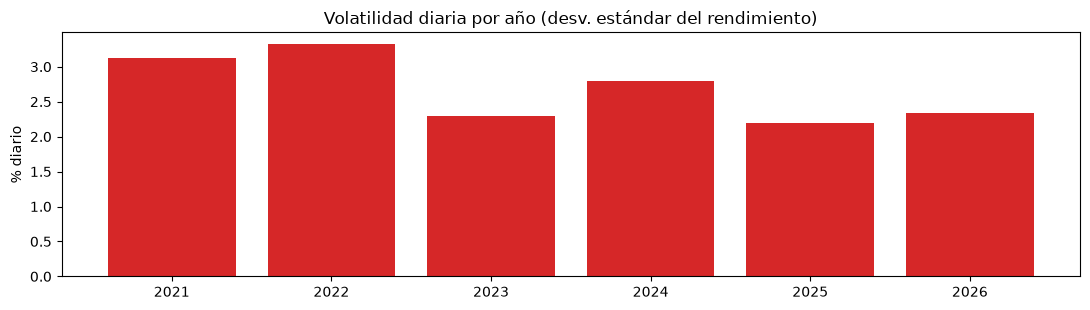

In [ ]:
por_anio = ind.assign(anio=ind.fecha.dt.year).groupby("anio").agg(
    ret_medio=("ret", "mean"), vol_diaria=("ret", "std"), ret_min=("ret", "min"), ret_max=("ret", "max"), dias=("ret", "count"))
display(por_anio)
por_anio.to_csv(SALIDA / "comportamiento_por_anio.csv")
fig, ax = plt.subplots(figsize=(11, 3.2)); ax.bar(por_anio.index.astype(str), por_anio.vol_diaria * 100, color="C3")
ax.set_ylabel("% diario"); ax.set_title("Volatilidad diaria por año (desv. estándar del rendimiento)"); plt.tight_layout()
plt.savefig(SALIDA / "figuras" / "volatilidad_por_anio.png", dpi=130); plt.show()

**Lectura.** La volatilidad no es constante: fue alta en 2021–2022 (≈ 3.1–3.3 % diario), bajó en 2023 y 2025 (≈ 2.2–2.3 %) y se concentra en rachas (periodos de picos). Esto cambia el riesgo y la escala de los errores entre años,
por eso la separación debe ser **cronológica** y los errores se interpretan respecto a una referencia en el mismo periodo. Una figura **no** implica capacidad predictiva.

## 4. Objetivo, ventanas y separación TR–VA–TE
- Se ordena por fecha y se construye `y_t = P_(t+1)/P_t − 1`; la última fila (sin P_(t+1) observable) se **retira** de los ejemplos (queda reservada para el pronóstico futuro).
- Cada ejemplo usa los **20 rendimientos más recientes hasta t** (ventana 20, `ret`). Se asigna a TR/VA/TE por la **fecha del objetivo** (70 % / 15 % / 15 %), **sin división aleatoria**.
- El primer ejemplo se fija el 2021-11-15 (primer día en que también pueden calcularse la SMA20 y la volatilidad de 20 días del Avance 5), de modo que **todas las entregas comparten la misma partición**.

In [ ]:
tabla_part = F.tabla_particiones(ej, idx)
display(tabla_part); tabla_part.to_csv(SALIDA / "tabla_particiones.csv", index=False)
print("Ejemplos totales:", len(ej), "| forma de X (ejemplos, pasos, variables):", ej.X.shape)
F.verificar_particion(ej, idx)    # lanza FugaError si los objetivos de TR/VA/TE se traslapan
f = ej.fecha_objetivo
print(f"Último objetivo de TR ({f[idx['TR']].max().date()}) < primero de VA ({f[idx['VA']].min().date()}) ✔")
print(f"Último objetivo de VA ({f[idx['VA']].max().date()}) < primero de TE ({f[idx['TE']].min().date()}) ✔")

,conjunto,n_ejemplos,emision_inicial,emision_final,objetivo_inicial,objetivo_final
0,TR,1269,2021-11-15,2025-05-06,2021-11-16,2025-05-07
1,VA,272,2025-05-07,2026-02-02,2025-05-08,2026-02-03
2,TE,272,2026-02-03,2026-11-01,2026-02-04,2026-11-02


Ejemplos totales: 1813 | forma de X (ejemplos, pasos, variables): (1813, 20, 1)
Último objetivo de TR (2025-05-07) < primero de VA (2025-05-08) ✔
Último objetivo de VA (2026-02-03) < primero de TE (2026-02-04) ✔


### Control de aprendizaje: una fila completa
Se muestran las fechas de entrada, la fecha de emisión y la fecha objetivo. **El modelo no conoce la respuesta al predecir** porque `y` usa P<sub>t+1</sub>, posterior a la emisión, y las 20 entradas terminan en el cierre de *t*.

In [ ]:
i = idx["VA"][0]; t = ej.idx_emision[i]
fila = pd.DataFrame({"fecha_entrada": d.fecha.iloc[t - VENTANA + 1: t + 1].dt.date.values, "rendimiento": ej.X[i, :, 0]})
print(fila.to_string(index=False))
print(f"\nFecha de emisión (cierre del día t) : {ej.fecha_emision[i].date()}   P_t   = {d.close.iloc[t]:,.2f}")
print(f"Fecha objetivo (día t+1)            : {ej.fecha_objetivo[i].date()}   P_t+1 = {d.close.iloc[t+1]:,.2f}")
print(f"y = P_t+1 / P_t − 1 = {ej.y[i]:.6f}")
assert ej.fecha_emision[i] == pd.Timestamp(d.fecha.iloc[t]) and ej.fecha_objetivo[i] == pd.Timestamp(d.fecha.iloc[t + 1])
assert d.fecha.iloc[t - VENTANA + 1: t + 1].max() == ej.fecha_emision[i], "ninguna entrada es posterior a la emisión"
assert np.isclose(ej.y[i], d.close.iloc[t + 1] / d.close.iloc[t] - 1)
print("✔ alineación verificada")

fecha_entrada  rendimiento
   2025-04-18    -0.005241
   2025-04-19     0.007254
   2025-04-20     0.001304
   2025-04-21     0.027527
   2025-04-22     0.067677
   2025-04-23     0.002753
   2025-04-24     0.002611
   2025-04-25     0.008268
   2025-04-26    -0.000777
   2025-04-27    -0.009425
   2025-04-28     0.013054
   2025-04-29    -0.007306
   2025-04-30    -0.000822
   2025-05-01     0.024255
   2025-05-02     0.004329
   2025-05-03    -0.010507
   2025-05-04    -0.016433
   2025-05-05     0.004581
   2025-05-06     0.021683
   2025-05-07     0.002374

Fecha de emisión (cierre del día t) : 2025-05-07   P_t   = 97,032.32
Fecha objetivo (día t+1)            : 2025-05-08   P_t+1 = 103,241.46
y = P_t+1 / P_t − 1 = 0.063990
✔ alineación verificada


## 5. Modelos de referencia: pronóstico cero y regresión lineal (MAE y RMSE en TR y VA)
Definiciones (escala original del rendimiento): error = estimado − real; **MAE** = promedio del error absoluto; **RMSE** = raíz del promedio del error al cuadrado.
El escalador se **ajusta solo con TR** y se aplica a VA sin reajustarlo. **TE no se utiliza en este avance.**

In [ ]:
X = ej.sel(("ret",))                                  # (n, 20, 1)
esc = F.EscaladorTR(("ret",)).ajustar(X[idx["TR"]], ej.y[idx["TR"]], ej.fecha_objetivo[idx["TR"]])
F.verificar_ajuste_solo_TR(esc, ej, idx)              # lanza FugaError si el escalador vio algo fuera de TR
Xs = esc.x(X).reshape(len(ej), -1)                    # 20 rezagos aplanados
lineal = LinearRegression().fit(Xs[idx["TR"]], ej.y[idx["TR"]])
pred = {"cero": lambda k: np.zeros(len(idx[k])), "regresion_lineal": lambda k: lineal.predict(Xs[idx[k]])}
filas = []
for nombre, fn in pred.items():
    for k in ("TR", "VA"):                            # TE queda excluido a propósito
        m = M.resumen(ej.y[idx[k]], fn(k))
        filas.append({"modelo": nombre, "conjunto": k, "n": m["n"], "MAE": m["mae"], "RMSE": m["rmse"]})
ref = pd.DataFrame(filas); display(ref)
ref.to_csv(SALIDA / "referencias_cap7.csv", index=False)
tabla_ref = ref.pivot(index="modelo", columns="conjunto", values=["MAE", "RMSE"]); display(tabla_ref.round(6))

,modelo,conjunto,n,MAE,RMSE
0,cero,TR,1269,0.019566,0.028498
1,cero,VA,272,0.014210,0.019259
2,regresion_lineal,TR,1269,0.019480,0.028229
3,regresion_lineal,VA,272,0.014545,0.019683


MAE                RMSE          
conjunto                TR        VA        TR        VA
modelo                                                  
cero              0.019566  0.014210  0.028498  0.019259
regresion_lineal  0.019480  0.014545  0.028229  0.019683

**Lectura.** El pronóstico cero (rendimiento esperado = 0) es una referencia fuerte: el rendimiento medio diario es ≈ 0 frente a una desviación de 2–3 %. La regresión lineal con 20 rezagos mejora un poco en TR (más flexible)
pero **empeora en VA**: lo aprendido en TR no generaliza al periodo siguiente (señal débil y cambio de régimen). La precisión direccional del pronóstico cero no está definida (su signo es 0) y no se usa en este avance.

## 6. Estudio técnico descriptivo e hipótesis verificable
Se observan tendencias, medias móviles y volatilidad (sección 3). Lo único que se calcula a continuación es una **descripción en TR** (nunca en VA ni TE):
la relación entre dos medidas técnicas en *t* y el rendimiento siguiente *y*.

,correlacion_con_y_(TR)
dist_SMA20 vs y,0.0036
vol20 vs y,-0.0111
dist_SMA20 vs |y|,-0.1108
vol20 vs |y|,0.1231


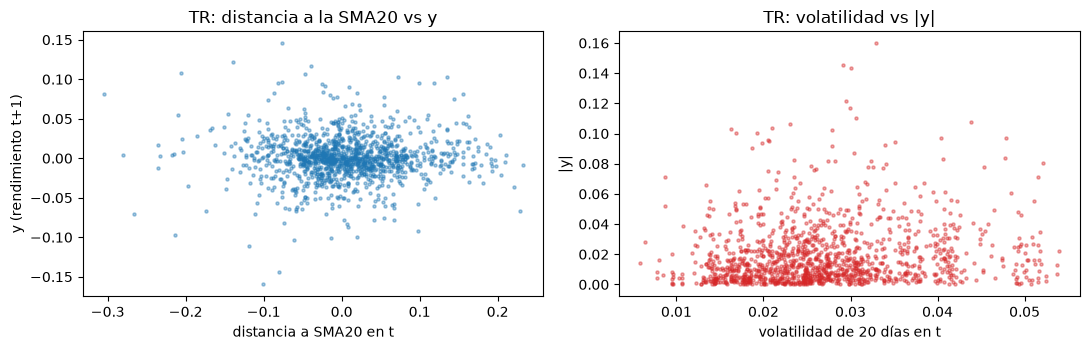

In [ ]:
sma20 = ind.sma20.to_numpy(); close = ind.close.to_numpy()
ie = ej.idx_emision[idx["TR"]]
dist = close[ie] / sma20[ie] - 1                      # distancia a la SMA20 en t (solo historia ≤ t)
vol = ind.vol20.to_numpy()[ie]
y_tr = ej.y[idx["TR"]]
desc = pd.DataFrame({"correlacion_con_y_(TR)": [np.corrcoef(dist, y_tr)[0, 1], np.corrcoef(vol, y_tr)[0, 1], np.corrcoef(dist, np.abs(y_tr))[0, 1], np.corrcoef(vol, np.abs(y_tr))[0, 1]]},
                    index=["dist_SMA20 vs y", "vol20 vs y", "dist_SMA20 vs |y|", "vol20 vs |y|"])
display(desc.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(dist, y_tr, s=5, alpha=0.4); ax[0].set_xlabel("distancia a SMA20 en t"); ax[0].set_ylabel("y (rendimiento t+1)"); ax[0].set_title("TR: distancia a la SMA20 vs y")
ax[1].scatter(vol, np.abs(y_tr), s=5, alpha=0.4, color="C3"); ax[1].set_xlabel("volatilidad de 20 días en t"); ax[1].set_ylabel("|y|"); ax[1].set_title("TR: volatilidad vs |y|")
plt.tight_layout(); plt.savefig(SALIDA / "figuras" / "descripcion_tecnica_TR.png", dpi=130); plt.show()

**Hipótesis técnica (verificable).**
**H1:** *la distancia respecto de la SMA de 20 cierres, `cierre/SMA20 − 1`, contiene información sobre el rendimiento del siguiente día.*
**Cómo se verificará (Avance 5):** se comparará el mismo modelo con rezagos vs. con rezagos + `dist_SMA20`, con el mismo protocolo, en **las mismas fechas de VA**; H1 se apoyará solo si MAE y RMSE de VA **bajan** de forma consistente.
**Hipótesis secundaria H2:** la volatilidad de 20 días se relaciona con la **magnitud** del movimiento siguiente (|y|), más que con su dirección.

**Lo que ya se ve (solo descriptivo, en TR):** la correlación de `dist_SMA20` (0.004) y de `vol20` (−0.011) con `y` es prácticamente nula; con la magnitud |y| aparecen correlaciones pequeñas (≈ −0.11 y +0.12),
compatibles con que los movimientos grandes ocurren en rachas de alta volatilidad.
**No se concluye** que una figura o una correlación implique capacidad predictiva: describir la magnitud del movimiento no sirve por sí solo para anticipar su dirección.

## 7. Seguimiento antes de avanzar
**¿Qué tendría que mejorar DL frente a pronosticar cero?** Debe lograr en **VA** un error menor que el del pronóstico cero, medido en la misma escala y fechas, y también menor que la regresión lineal:

In [ ]:
cero_va = ref[(ref.modelo == "cero") & (ref.conjunto == "VA")].iloc[0]; lin_va = ref[(ref.modelo == "regresion_lineal") & (ref.conjunto == "VA")].iloc[0]
umbral = pd.DataFrame({"MAE VA": [cero_va.MAE, lin_va.MAE], "RMSE VA": [cero_va.RMSE, lin_va.RMSE]}, index=["cero (a superar)", "regresión lineal"])
display(umbral.round(6))
print(f"→ Para aportar, un modelo profundo debe obtener RMSE de VA < {cero_va.RMSE:.5f} y MAE de VA < {cero_va.MAE:.5f}, "
      "y además superar a la regresión lineal; una menor pérdida en TR por sí sola no basta.")

,MAE VA,RMSE VA
cero (a superar),0.014210,0.019259
regresión lineal,0.014545,0.019683


→ Para aportar, un modelo profundo debe obtener RMSE de VA < 0.01926 y MAE de VA < 0.01421, y además superar a la regresión lineal; una menor pérdida en TR por sí sola no basta.


**Comprobaciones previas a avanzar** (se ejecutan como *asserts* y quedan registradas):

In [ ]:
chk = []
chk.append(("Datos ordenados, sin duplicados, finitos y > 0", bool(d.fecha.is_unique and d.fecha.is_monotonic_increasing and (d[data.PRECIOS] > 0).all().all())))
chk.append(("Objetivo = P(t+1)/P(t) − 1 en todas las filas", bool(np.allclose(ej.y, d.close.to_numpy()[ej.idx_emision + 1] / d.close.to_numpy()[ej.idx_emision] - 1))))
chk.append(("Emisión < objetivo en todos los ejemplos", bool((ej.fecha_emision < ej.fecha_objetivo).all())))
chk.append(("TR < VA < TE por fecha del objetivo", bool(f[idx["TR"]].max() < f[idx["VA"]].min() and f[idx["VA"]].max() < f[idx["TE"]].min())))
chk.append(("Escalador ajustado solo con TR (n y fecha máxima)", bool(esc.n_ajuste == len(idx["TR"]) and pd.Timestamp(esc.fecha_max_objetivo_ajuste) <= f[idx["TR"]].max())))
chk.append(("Predicciones y métricas finitas", bool(np.isfinite(ref[["MAE", "RMSE"]].to_numpy()).all())))
chk.append(("TE no utilizado para ninguna métrica", True))
chk = pd.DataFrame(chk, columns=["control", "cumple"]); display(chk)
assert chk.cumple.all()
bit.registrar("preparación", "sin incidentes en los datos", "auditoría sin duplicados, faltantes ni valores no válidos", "se aplicó la regla de limpieza (0 filas cambiadas)", "índice único, orden cronológico y valores finitos verificados")
bit.guardar(SALIDA / "bitacora.csv")
print("Archivos generados en", SALIDA, ":", sorted(p.name for p in SALIDA.iterdir()))

,control,cumple
0,"Datos ordenados, sin duplicados, finitos y > 0",True
1,Objetivo = P(t+1)/P(t) − 1 en todas las filas,True
2,Emisión < objetivo en todos los ejemplos,True
3,TR < VA < TE por fecha del objetivo,True
4,Escalador ajustado solo con TR (n y fecha máxima),True
5,Predicciones y métricas finitas,True
6,TE no utilizado para ninguna métrica,True


Archivos generados en C:\Users\alexg\Documents\Escuela\Quinto Semestre\Ciencia de Datos\Proyecto_final\Avance 1 Capitulo 7\salidas : ['bitacora.csv', 'comportamiento_por_anio.csv', 'diccionario_datos.csv', 'ficha_activo.csv', 'figuras', 'referencias_cap7.csv', 'tabla_particiones.csv']


## Resumen del Avance 1
- **Datos auditados:** 1,853 observaciones diarias de BTC-USD (2021-10-07 → 2026-11-02), sin faltantes ni duplicados; extremos reales conservados.
- **Partición cronológica 70/15/15** por fecha del objetivo (tabla en la sección 4) y escalador ajustado solo con TR.
- **Dos referencias:** pronóstico cero y regresión lineal con 20 rezagos; MAE/RMSE en TR y VA (sección 5). TE reservado.
- **Hipótesis técnica:** H1 (distancia a SMA20) y H2 (volatilidad vs magnitud), a verificar en el Avance 5.
- **Para DL:** superar a cero y a la regresión lineal en VA.